## **_Noah Smith - HOMEWORK ASSIGNMENT_** 3!!!!!!


**_Question #1_** :	Projectile Motion with Air Resistance – Maximum Range


In [1]:
import math
import numpy as np

grav = 9.81
rho = 1.225

def landing_range(speed, theta_deg, y0, Cd, area, mass, tau=0.001):
    """Range of a projectile with quadratic drag, using the same
    average-velocity update as the notebook. Landing point is found by
    linear interpolation between the last point above and first below y=0."""
    k = -0.5 * Cd * rho * area / mass
    th = math.radians(theta_deg)
    x, y = 0.0, y0
    vx, vy = speed * math.cos(th), speed * math.sin(th)
    while True:
        v = math.hypot(vx, vy)
        ax = k * v * vx
        ay = k * v * vy - grav
        vxn, vyn = vx + tau * ax, vy + tau * ay
        xn = x + tau * (vx + vxn) / 2.0
        yn = y + tau * (vy + vyn) / 2.0
        if yn < 0 and vyn < 0:
            f = y / (y - yn)              # fraction of step to reach y = 0
            return x + f * (xn - x)
        x, y, vx, vy = xn, yn, vxn, vyn

def best_angle(speed, y0, Cd, area, mass, tau=0.001):
    # coarse scan, then refine around the best angle
    angles = np.arange(5, 85.01, 1.0)
    R = [landing_range(speed, a, y0, Cd, area, mass, tau) for a in angles]
    a0 = angles[int(np.argmax(R))]
    fine = np.arange(a0 - 1.0, a0 + 1.0001, 0.05)
    Rf = [landing_range(speed, a, y0, Cd, area, mass, tau) for a in fine]
    i = int(np.argmax(Rf))
    return fine[i], Rf[i]

(a)	Modify the Jupyter Notebook called graph_projectile.ipynb (in the Week4 folder) to calculate the angle for maximum range for the initial velocity and position values considered (i.e. a golf ball launched at 55.8 m/s from ground level, and returning to ground level).

In [2]:
ang, rng = best_angle(55.8, 0.0, 0.20, 0.001432, 0.04593)
print(f"Golf ball:  best angle = {ang:.2f} deg, range = {rng:.1f} m")
print(f"  no-drag range at 45 deg = {55.8**2/grav:.1f} m")

Golf ball:  best angle = 40.40 deg, range = 175.0 m
  no-drag range at 45 deg = 317.4 m


(b) Now modify the code to consider a baseball launched from 1 m above ground level at 100 mph (converted to m/s). What is the ideal launch angle in this case?

In [3]:
v = 100 * 0.44704
d = 0.0737
area_b = math.pi * (d / 2) ** 2
for Cd in (0.3, 0.4, 0.5):
    ang, rng = best_angle(v, 1.0, Cd, area_b, 0.145)
    print(f"Baseball Cd={Cd}: best angle = {ang:.2f} deg, range = {rng:.1f} m ({rng*3.281:.0f} ft)")

Baseball Cd=0.3: best angle = 40.45 deg, range = 117.3 m (385 ft)
Baseball Cd=0.4: best angle = 39.55 deg, range = 104.3 m (342 ft)
Baseball Cd=0.5: best angle = 38.75 deg, range = 94.3 m (310 ft)


The best angle is about 39 degrees for a baseball, slightly disagreeing with the websites findings through experimental data which says the ideal hit known as "barreled" at 100MPH lies between 24 and 33 degrees.

**_Question #2_** : Investigating a Pseudorandom Number Generator


(a) Run two generators using the same seed and compare their first ten values. Change the seed and repeat the comparison. Explain what the results demonstrate about pseudorandom numbers and reproducibility.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 12

def make_mersenne_twister(seed):
    # Return a NumPy random-number generator using MT19937.
    return np.random.Generator(np.random.MT19937(seed))

SEED = 441

rng_a = make_mersenne_twister(SEED)       # seed 441
rng_b = make_mersenne_twister(SEED)       # same seed again
rng_c = make_mersenne_twister(SEED + 1)   # different seed (442)

values_a = rng_a.random(10)
values_b = rng_b.random(10)
values_c = rng_c.random(10)

print("Seed 441 (generator 1):", values_a)
print("Seed 441 (generator 2):", values_b)
print("Seed 442:              ", values_c)
print()
print("Same seed identical?     ", np.array_equal(values_a, values_b))
print("Different seed identical?", np.array_equal(values_a, values_c))

Seed 441 (generator 1): [0.17678155 0.67420814 0.75985841 0.35877555 0.14738443 0.77007201
 0.45852638 0.72038949 0.11526713 0.34840785]
Seed 441 (generator 2): [0.17678155 0.67420814 0.75985841 0.35877555 0.14738443 0.77007201
 0.45852638 0.72038949 0.11526713 0.34840785]
Seed 442:               [0.36378316 0.26195083 0.53098252 0.83542238 0.46021437 0.04250378
 0.22229631 0.77363956 0.14498674 0.39821465]

Same seed identical?      True
Different seed identical? False



1. When two generators use the same seed, they produce exactly the same ten values in the same order.
2. When the seed is changed (441 to 442), the sequence is completely different, with no visible relationship to the first one.
3. These results show that pseudorandom numbers are deterministic. The sequence looks random, but the seed fully determines it, because the generator is an algorithm that updates an internal state starting from the seed. This makes simulations reproducible: anyone who uses the same seed and code gets identical numbers and results.

(b) Generate N uniformly distributed numbers between zero and one for N = 100, 1,000, 10,000, and 100,000. For each sample, plot a histogram and calculate the sample mean and variance. Compare them with the theoretical values

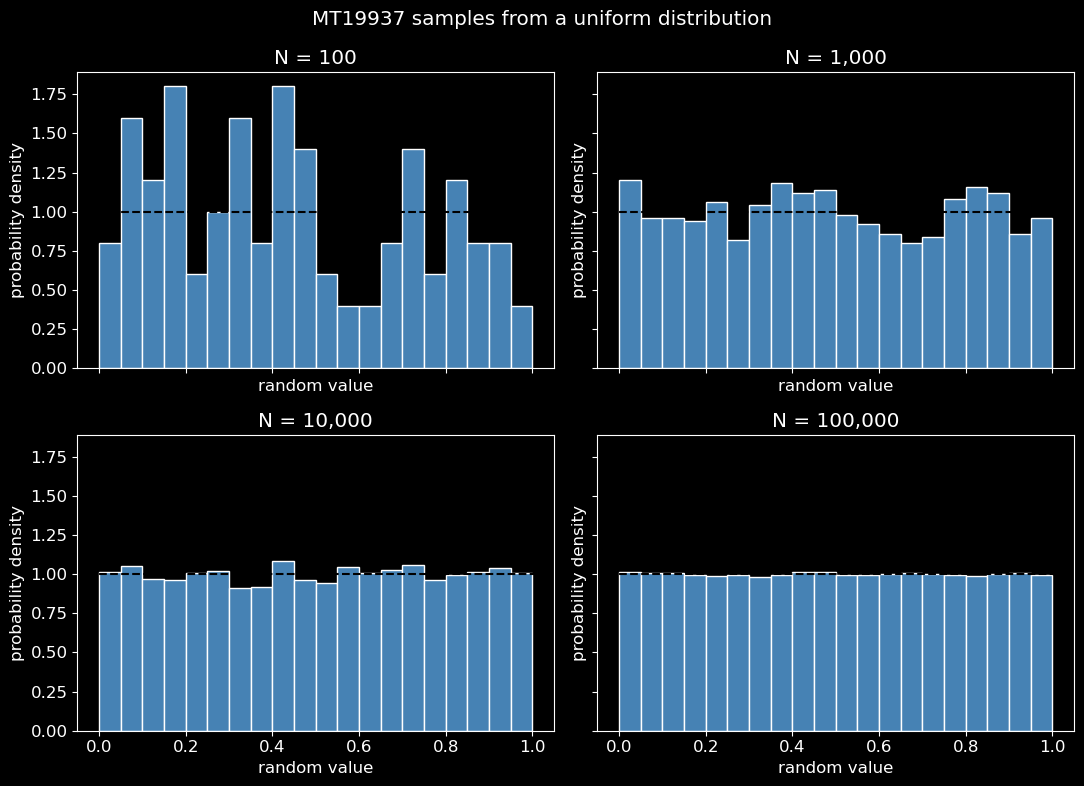

In [5]:
sample_sizes = [100, 1_000, 10_000, 100_000]
theoretical_mean = 1 / 2
theoretical_variance = 1 / 12

# Re-create the generator so this section gives the same results each time.
rng = make_mersenne_twister(SEED)

samples = {}
rows = []

for n in sample_sizes:
    sample = rng.random(n)
    samples[n] = sample
    rows.append(
        {
            "N": n,
            "sample mean": np.mean(sample),
            "sample variance": np.var(sample),
            "mean absolute error": abs(np.mean(sample) - theoretical_mean),
            "variance absolute error": abs(np.var(sample) - theoretical_variance),
        }
    )

results = pd.DataFrame(rows)
results

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)

for ax, n in zip(axes.flat, sample_sizes):
    ax.hist(samples[n], bins=20, range=(0, 1), density=True,
            color="steelblue", edgecolor="white")
    ax.axhline(1.0, color="black", linestyle="--", label="uniform density")
    ax.set_title(f"N = {n:,}")
    ax.set_xlabel("random value")
    ax.set_ylabel("probability density")

fig.suptitle("MT19937 samples from a uniform distribution")
fig.tight_layout()
plt.show()

(c) Plot the absolute errors in the sample mean and variance as functions of N, using logarithmic scales where appropriate. Describe how the agreement with the theoretical values changes as the sample size increases.

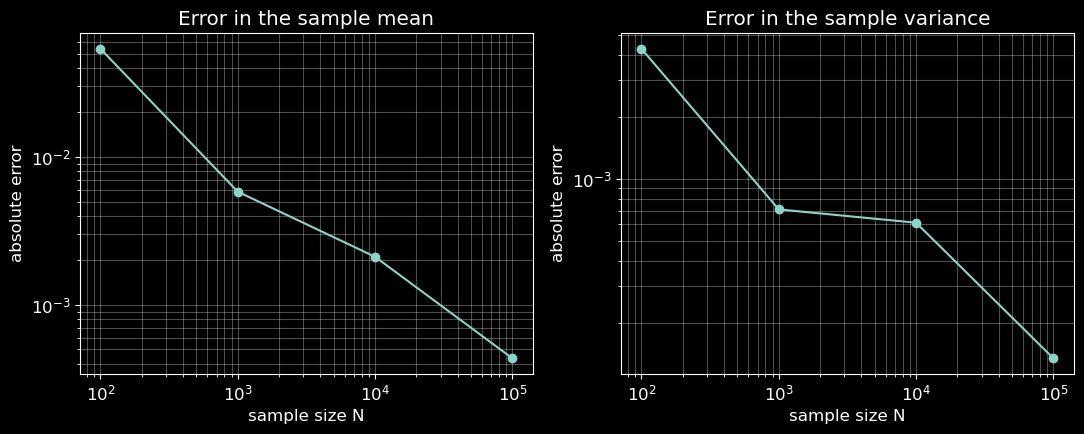

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].loglog(results["N"], results["mean absolute error"], "o-")
axes[0].set_xlabel("sample size N")
axes[0].set_ylabel("absolute error")
axes[0].set_title("Error in the sample mean")
axes[0].grid(True, which="both", alpha=0.3)

axes[1].loglog(results["N"], results["variance absolute error"], "o-")
axes[1].set_xlabel("sample size N")
axes[1].set_ylabel("absolute error")
axes[1].set_title("Error in the sample variance")
axes[1].grid(True, which="both", alpha=0.3)

fig.tight_layout()
plt.show()


On the log-log plots, both the mean error and the variance error decrease as N increases, following a roughly straight line with a negative slope. The expected scaling error is proportional to 1/sqrt(N), which gives a slope of about -1/2: a 100-fold increase in N should reduce the typical error by about a factor of 10. For example, the mean error fell from about 0.054 at N = 100 to about 0.0004 at N = 100,000.

The decrease is not perfectly smooth. The variance error changed very little between N = 1,000 (0.00071) and N = 10,000 (0.00061). This is expected because each sample is a random draw, so the error stays around the overall trend. Agreement with the theoretical values improves as the sample size increases.

(d) Explain why pseudorandom-number generators are useful in scientific simulations, why recording the seed is important, and why passing these simple tests does not prove that a generator is perfectly random.


1. **Why pseudo random number generators are useful in scientific simulations:** Many methods, such as Monte Carlo integration, stochastic simulations, and random sampling, need large amounts of random-looking numbers. A pseudorandom-number generator produces them quickly, with good uniformity and a very long period (2^19937 - 1 for the Mersenne Twister). Because it is not actually random, a simulation can be rerun and debugged, which isn't possible with truly random input.

2. **Why record the seed:** The seed determines the entire sequence, recording it lets you else reproduce a simulation exactly. This is needed for debugging, verifying results, and comparing changes in code. Without the seed, an unusual result could never be recreated.

3. **Why these tests don't prove the generator is perfectly random:** The tests only check the mean, the variance, and the overall histogram shape. A sequence can pass all of these and still have serious flaws, such as correlations between consecutive values or hidden patterns. For example, the ordered sequence 0.00, 0.01, ..., 0.99 has an excellent mean and variance but is clearly not random. Also, the output is fully determined by the seed, so it is never truly random. Properly testing a generator requires much more testing than simply the mean and variance.

**_Question #3_** : Adding a new method to evaluate the central probability in Bertrand’s Paradox:


Method 4 probability = 0.6096


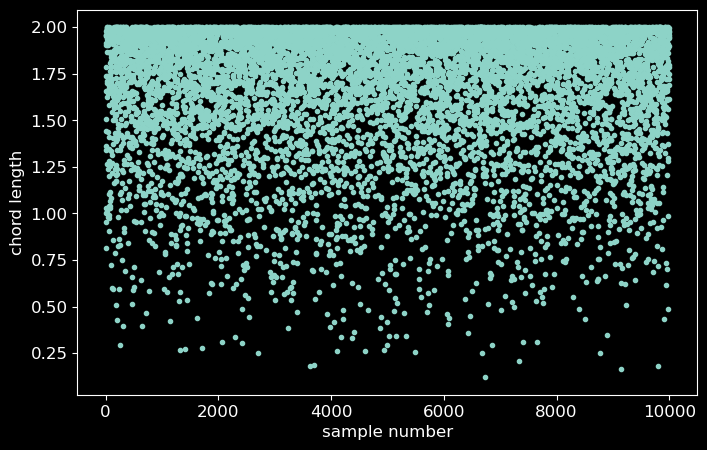

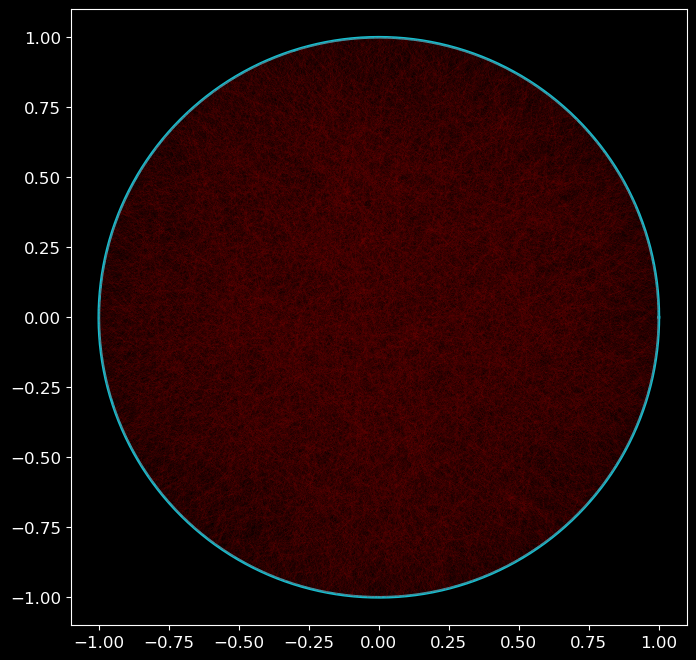

In [10]:
n = 10000   # number of chords

# Unit circle for plotting
thetac = np.linspace(0, 2*np.pi, 1000)
xc = np.cos(thetac)
yc = np.sin(thetac)

# ---------- Method 4: random point + random direction ----------
# Step 1: random point uniformly distributed by area inside the unit circle
chosen = 0
px = np.zeros(n)
py = np.zeros(n)

while chosen < n:
    x1 = np.random.uniform(-1, 1)
    y1 = np.random.uniform(-1, 1)
    if np.sqrt(x1**2 + y1**2) <= 1:
        px[chosen] = x1
        py[chosen] = y1
        chosen += 1

# Step 2: random direction for the chord through each point
phi = np.random.uniform(0, 2*np.pi, n)
ux = np.cos(phi)
uy = np.sin(phi)

# Step 3: intersect the line p + t*u with the unit circle
# |p + t u|^2 = 1  ->  t^2 + 2 b t + (|p|^2 - 1) = 0,  where b = p . u
b4 = px*ux + py*uy
disc = np.sqrt(b4**2 + 1 - (px**2 + py**2))

t1 = -b4 - disc
t2 = -b4 + disc

xint5 = px + t1*ux
yint5 = py + t1*uy
xint6 = px + t2*ux
yint6 = py + t2*uy

length4 = np.sqrt((xint5 - xint6)**2 + (yint5 - yint6)**2)

# Probability that the chord is longer than a side of the inscribed triangle
count4 = np.sum(length4 > np.sqrt(3))
print(f"Method 4 probability = {count4/n}")

# ---------- Plots ----------
# Chord length for each sample
plt.figure()
plt.plot(np.arange(n), length4, '.')
plt.xlabel("sample number")
plt.ylabel("chord length")
plt.grid(False)

# All chords drawn inside the circle
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.plot(xc, yc, color='tab:cyan', linewidth=2)
ax.grid(False)
for i in range(n):
    ax.plot([xint5[i], xint6[i]], [yint5[i], yint6[i]], 'r', linewidth=0.01)
ax.set_aspect('equal')

plt.show()


- Method 4 is the largest of the four because it is favorable to long chords. Random directions through a point favor chords that pass near the center making long chords are more likely than in Methods 1 and 3.
- It is not the same as Method 3. Both use a uniformly random point in the disk, but in Method 3 the point is the chord's *midpoint*, which fixes the chord completely. In Method 4 the point is only some point *on* the chord, so the chord is determined by the extra random angle, and the chords come out differently distributed.